In [1]:
import pandas as pd
import numpy as np
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
import matplotlib.pyplot as plt

In [2]:
df = pd.read_csv("sales_data_sample.csv",encoding='latin6')

In [3]:
df

,ORDERNUMBER,QUANTITYORDERED,PRICEEACH,ORDERLINENUMBER,SALES,ORDERDATE,STATUS,QTR_ID,MONTH_ID,YEAR_ID,...,ADDRESSLINE1,ADDRESSLINE2,CITY,STATE,POSTALCODE,COUNTRY,TERRITORY,CONTACTLASTNAME,CONTACTFIRSTNAME,DEALSIZE
0,10107,30,95.70,2,2871.00,2/24/2003 0:00,Shipped,1,2,2003,...,897 Long Airport Avenue,NaN,NYC,NY,10022,USA,NaN,Yu,Kwai,Small
1,10121,34,81.35,5,2765.90,5/7/2003 0:00,Shipped,2,5,2003,...,59 rue de l'Abbaye,NaN,Reims,NaN,51100,France,EMEA,Henriot,Paul,Small
2,10134,41,94.74,2,3884.34,7/1/2003 0:00,Shipped,3,7,2003,...,27 rue du Colonel Pierre Avia,NaN,Paris,NaN,75508,France,EMEA,Da Cunha,Daniel,Medium
3,10145,45,83.26,6,3746.70,8/25/2003 0:00,Shipped,3,8,2003,...,78934 Hillside Dr.,NaN,Pasadena,CA,90003,USA,NaN,Young,Julie,Medium
4,10159,49,100.00,14,5205.27,10/10/2003 0:00,Shipped,4,10,2003,...,7734 Strong St.,NaN,San Francisco,CA,NaN,USA,NaN,Brown,Julie,Medium
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2818,10350,20,100.00,15,2244.40,12/2/2004 0:00,Shipped,4,12,2004,...,"C/ Moralzarzal, 86",NaN,Madrid,NaN,28034,Spain,EMEA,Freyre,Diego,Small
2819,10373,29,100.00,1,3978.51,1/31/2005 0:00,Shipped,1,1,2005,...,Torikatu 38,NaN,Oulu,NaN,90110,Finland,EMEA,Koskitalo,Pirkko,Medium
2820,10386,43,100.00,4,5417.57,3/1/2005 0:00,Resolved,1,3,2005,...,"C/ Moralzarzal, 86",NaN,Madrid,NaN,28034,Spain,EMEA,Freyre,Diego,Medium
2821,10397,34,62.24,1,2116.16,3/28/2005 0:00,Shipped,1,3,2005,...,1 rue Alsace-Lorraine,NaN,Toulouse,NaN,31000,France,EMEA,Roulet,Annette,Small


In [4]:
x= df[["QUANTITYORDERED","SALES"]]

In [5]:
x

,QUANTITYORDERED,SALES
0,30,2871.00
1,34,2765.90
2,41,3884.34
3,45,3746.70
4,49,5205.27
...,...,...
2818,20,2244.40
2819,29,3978.51
2820,43,5417.57
2821,34,2116.16


In [6]:
scaler = StandardScaler()
x_scaled = scaler.fit_transform(x)

In [7]:
x_scaled
wcss =[]

In [14]:
for k in range(1,11):
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    km.fit(x_scaled)
    wcss.append(km.inertia_)

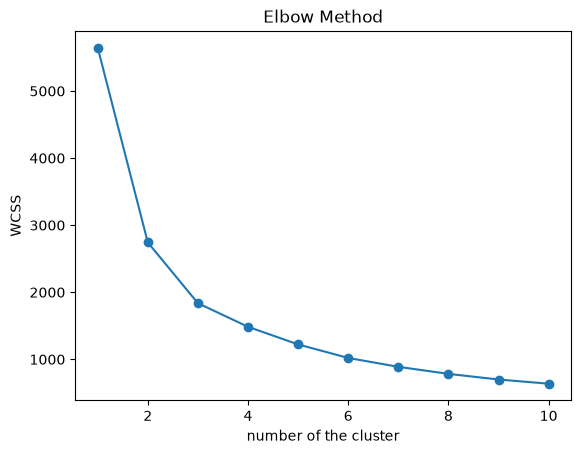

In [15]:
plt.plot(range(1,11),wcss,marker='o')
plt.xlabel("number of the cluster")
plt.ylabel("WCSS")
plt.title("Elbow Method")
plt.show()

In [16]:
k =3
model =KMeans(n_clusters = k,random_state = 42,n_init =10)
df["Cluster"] = model.fit_predict(x_scaled)

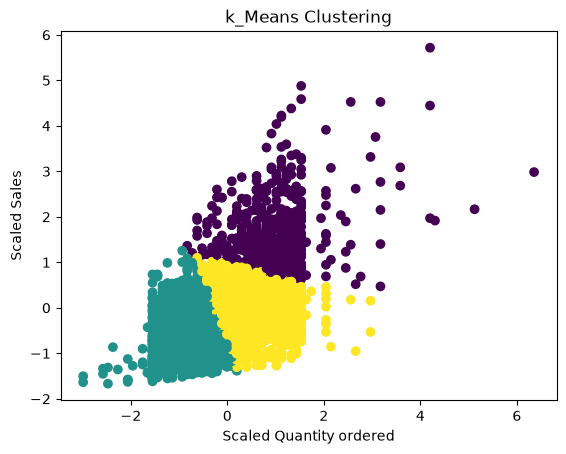

In [17]:
plt.scatter(x_scaled[:,0],x_scaled[:,1],c=df["Cluster"])
plt.xlabel("Scaled Quantity ordered")
plt.ylabel("Scaled Sales")
plt.title("k_Means Clustering")
plt.show()

In [20]:
print("Number of Clusters",k)
print(df[["QUANTITYORDERED", "SALES", "Cluster"]].head())

Number of Clusters 3
   QUANTITYORDERED    SALES  Cluster
0               30  2871.00        1
1               34  2765.90        2
2               41  3884.34        2
3               45  3746.70        2
4               49  5205.27        0
